# AMP classification: sensitivity and CPU deployment cost

中文说明：本Notebook保留指定的15种方法；两张图均为200 × 200 mm，Arial字体。坐标轴和主刻度线宽均为1.5 pt，刻度长6.5 pt。可在下方设置区调整字号、线宽和散点大小；每张图由一个独立代码块输出。纵轴AUPRC采用average precision定义。原始分析报告未修改。

English: Two 200 × 200 mm vector figures for the selected 15 methods. All text uses Arial. Axis and major-tick widths are 1.5 pt, with 6.5 pt major ticks. Each figure has a separate execution cell; formatting controls and editable label positions are in the setup cell. AUPRC is calculated as average precision.

Run with the **ccseg** kernel from this directory. The two source CSV files are provided beside this notebook. The data are from `mic128_classifier_v3_classic_expansion/tables/`; no models are retrained here.


Repository release: the two CSV inputs contain only the 15 selected methods. The fixed method-colour mapping preserves the approved figures. Install the figure requirements and register the kernel in your own environment; the original executed kernel was ccseg.


In [1]:
"""Publication PDFs: sensitivity/FPR and AUPRC versus single-thread CPU latency.
Run from any directory with Python + numpy/pandas/matplotlib.
All scientific inputs are copied beside this script; output canvases are exactly square.
"""
from pathlib import Path
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.text import Text
from matplotlib.ticker import FixedLocator,NullLocator

ROOT=Path.cwd()
# Formatting controls: mm for canvas/axes; pt for fonts, strokes and ticks.
SIZE_MM=200
AXIS_WIDTH=1.5
TICK_WIDTH=1.5
TICK_LENGTH=6.5
TICK_FONT=12
LABEL_FONT=13
METHOD_FONT=11.2
POINT_SIZE=78
EXCLUDE={'DeepAMP','CatBoost-Recall','Das','CatBoost','APEX','Logistic'}

for p in Path('/usr/share/fonts/truetype/msttcorefonts').glob('*.ttf'):
    if 'arial' in p.name.lower():font_manager.fontManager.addfont(str(p))
ARIAL=font_manager.findfont('Arial',fallback_to_default=False)
plt.rcParams.update({'font.family':'Arial','font.size':12,'axes.labelsize':LABEL_FONT,
  'axes.linewidth':AXIS_WIDTH,'axes.edgecolor':'#252B31','text.color':'#252B31',
  'axes.labelcolor':'#252B31','xtick.color':'#252B31','ytick.color':'#252B31',
  'xtick.labelsize':TICK_FONT,'ytick.labelsize':TICK_FONT,'pdf.fonttype':42,
  'ps.fonttype':42,'svg.fonttype':'none','savefig.facecolor':'white','axes.unicode_minus':False})
summary=pd.read_csv(ROOT/'test_classwise_summary.csv',float_precision='round_trip')
timing=pd.read_csv(ROOT/'cpu_timing.csv',float_precision='round_trip')
all_order=summary.query('operating_point=="balanced" and `class`=="AMP"').sort_values('AUROC_mean',ascending=False).model.tolist()
ORDER=[m for m in all_order if m not in EXCLUDE]
assert len(ORDER)==15 and len(set(ORDER))==15
# Fixed approved colours, independent of which rows are bundled.
color={'ExtraTrees': '#43A047', 'Cascade': '#7C6BD9', 'CatBoost-Tuned': '#F97316', 'XGBoost': '#202020', 'HistGradientBoosting': '#D0A300', 'TinyCNN': '#56B4E9', 'RBFSVM': '#8C564B', 'LightGBM': '#DE5B5B', 'RF': '#31688E', 'AdaBoost': '#8556A2', 'LinearSVM': '#357A38', 'GBDT': '#0083A3', 'EBM': '#8C7867', 'SimpleLogistic': '#988A00', 'Dummy': '#B3436C'}
INK='#252B31';MUTED='#59636E';GREEN='#159D82';ORANGE='#E98032'

def rect_mm(left,bottom,width,height):return np.array([left,bottom,width,height])/SIZE_MM

def clean(ax):
    ax.spines[['top','right']].set_visible(False)
    ax.tick_params(axis='both',direction='out',width=TICK_WIDTH,length=TICK_LENGTH,pad=6)
    ax.grid(False)

def part(cls,point):
    return summary.query('`class`==@cls and operating_point==@point').set_index('model').loc[ORDER]

def save(fig,name,extra=None):
    fig.canvas.draw();renderer=fig.canvas.get_renderer();canvas=fig.bbox
    outside=[]
    for text in fig.findobj(Text):
        if not text.get_visible() or not text.get_text().strip():continue
        b=text.get_window_extent(renderer)
        if b.width and b.height and (b.x0<-1 or b.y0<-1 or b.x1>canvas.x1+1 or b.y1>canvas.y1+1):outside.append(text.get_text())
    if outside:raise AssertionError(('Text outside canvas',outside))
    # Do not use bbox_inches='tight': both PDFs must keep the exact 200 x 200 mm MediaBox.
    fig.savefig(ROOT/f'{name}.pdf')
    fig.savefig(ROOT/f'{name}.svg')
    fig.savefig(ROOT/f'{name}.png',dpi=350)
    fig.savefig(ROOT/f'{name}_preview.png',dpi=150)
    layout={'canvas_mm':[SIZE_MM,SIZE_MM],'font':'Arial','font_file':ARIAL,'axis_width_pt':AXIS_WIDTH,
            'major_tick_width_pt':TICK_WIDTH,'major_tick_length_pt':TICK_LENGTH,
            'major_tick_font_pt':TICK_FONT,'methods':ORDER,'off_canvas_text':outside}
    if extra:layout.update(extra)
    (ROOT/f'{name}_layout.json').write_text(json.dumps(layout,indent=2)+'\n')
    return layout

def sensitivity():
    fig=plt.figure(figsize=(SIZE_MM/25.4,SIZE_MM/25.4),facecolor='white')
    fig.text(.055,.955,'Sensitivity and false-positive burden',fontsize=16,weight='bold',ha='left')
    fig.text(.055,.919,'Test200 | 15 methods | fixed validation-derived thresholds',fontsize=10.8,color=MUTED)
    points=['balanced','recall95','recall98'];titles=['Maximum MCC','Recall ≥95%','Recall ≥98%']
    left=53.;gap=4.5;width=(SIZE_MM-left-7-2*gap)/3.;bottom=37.;height=133.
    rows=[]
    for j,(point,title) in enumerate(zip(points,titles)):
        ax=fig.add_axes(rect_mm(left+j*(width+gap),bottom,width,height));clean(ax)
        for k in range(0,15,2):ax.axhspan(k-.5,k+.5,color='#F2F5F7',lw=0,zorder=0)
        a=part('AMP',point);b=part('non-AMP',point);y=np.arange(15)
        ax.errorbar(a.Recall_mean,y-.16,xerr=a.Recall_std,fmt='o',ms=6.2,
            mfc=GREEN,mec=GREEN,color=GREEN,elinewidth=1.6,capsize=3,capthick=1.4,zorder=3)
        ax.errorbar(1-b.Recall_mean,y+.16,xerr=b.Recall_std,fmt='o',ms=6.2,
            mfc='white',mec=ORANGE,mew=1.6,color=ORANGE,elinewidth=1.6,capsize=3,capthick=1.4,zorder=3)
        ax.set(xlim=(-.045,1.055),ylim=(14.65,-.65),xticks=[0,.5,1],xticklabels=['0.0','0.5','1.0'],yticks=y)
        ax.set_yticklabels(ORDER if j==0 else ['']*15,fontsize=METHOD_FONT)
        if j>0:ax.tick_params(axis='y',length=0)
        ax.set_title(title,fontsize=11.7,weight='bold',pad=11)
        for m in ORDER:rows.append(dict(model=m,operating_point=point,AMP_recall_mean=a.loc[m,'Recall_mean'],
            AMP_recall_sd=a.loc[m,'Recall_std'],nonAMP_FPR_mean=1-b.loc[m,'Recall_mean'],nonAMP_FPR_sd=b.loc[m,'Recall_std']))
    fig.text((left+(SIZE_MM-left-7)/2)/SIZE_MM,.115,'Fraction of the corresponding class',ha='center',fontsize=12)
    handles=[Line2D([],[],ls='',marker='o',ms=7,mfc=GREEN,mec=GREEN,label='AMP sensitivity'),
             Line2D([],[],ls='',marker='o',ms=7,mfc='white',mec=ORANGE,mew=1.6,label='Non-AMP false-positive rate')]
    fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.53,.052),ncol=2,frameon=False,
               fontsize=10.8,handletextpad=.65,columnspacing=1.5)
    fig.text(.055,.031,'Mean ± SD across seeds 120–124; 100 AMP and 100 non-AMP.',fontsize=10,color=MUTED)
    pd.DataFrame(rows).to_csv(ROOT/'sensitivity_source_data.csv',index=False)
    return save(fig,'Sensitivity_and_false_positive_burden'),fig

# Explicit, editable text positions in data coordinates; leaders preserve point identity.
LABELS={
 'CatBoost-Tuned':(3.15,1.012,'left'), 'XGBoost':(13.5,1.035,'center'),
 'ExtraTrees':(46.,1.025,'left'), 'RBFSVM':(46.,.987,'left'),
 'HistGradientBoosting':(46.,.949,'left'), 'RF':(46.,.911,'left'),
 'AdaBoost':(46.,.873,'left'), 'LinearSVM':(38.,.827,'left'),
 'TinyCNN':(3.15,.938,'left'), 'LightGBM':(13.,.862,'center'),
 'GBDT':(3.15,.876,'left'), 'EBM':(3.15,.827,'left'),
 'SimpleLogistic':(6.8,.752,'left'), 'Dummy':(6.6,.505,'left'),
 'Cascade':(260.,1.003,'center')}

def cost():
    fig=plt.figure(figsize=(SIZE_MM/25.4,SIZE_MM/25.4),facecolor='white')
    fig.text(.055,.955,'Accuracy and CPU deployment cost',fontsize=16,weight='bold',ha='left')
    fig.text(.055,.919,'AMP AUPRC | 200-peptide batch | single CPU thread',fontsize=10.8,color=MUTED)
    ax=fig.add_axes(rect_mm(24.,42.,168.,129.));clean(ax)
    ax.set_xscale('log');ax.set(xlim=(2.5,550),ylim=(.45,1.065))
    ticks=[5,10,20,50,100,200,500];ax.xaxis.set_major_locator(FixedLocator(ticks));ax.set_xticklabels([str(v) for v in ticks]);ax.xaxis.set_minor_locator(NullLocator())
    ax.set_yticks(np.arange(.5,1.01,.1));ax.set_xlabel('CPU time for 200 peptides (ms)',labelpad=11)
    ax.set_ylabel('AMP AUPRC',labelpad=11)
    d=part('AMP','balanced');t=timing.query('threads==1 and batch==200').set_index('model').loc[ORDER]
    assert len(t)==15 and t.index.is_unique
    labels=[];source=[]
    for m in ORDER:
        x=float(t.loc[m,'median_ms']);y=float(d.loc[m,'AUPRC_mean']);err=float(d.loc[m,'AUPRC_std'])
        ax.errorbar(x,y,yerr=err,fmt='none',ecolor=color[m],elinewidth=1.7,capsize=3.4,capthick=1.5,zorder=3)
        ax.scatter([x],[y],s=POINT_SIZE,marker='D' if m=='CatBoost-Tuned' else 'o',
                   c=[color[m]],edgecolors='white',linewidths=.75,zorder=4)
        lx,ly,ha=LABELS[m]
        text=ax.text(lx,ly,m,ha=ha,va='center',fontsize=11.3,color=INK,zorder=6)
        labels.append((m,text,x,y))
        source.append(dict(model=m,AUPRC_mean=y,AUPRC_sd=err,CPU_200_median_ms=x,
                           CPU_200_p95_ms=float(t.loc[m,'p95_ms']),threads=1,timing_seed=123))
    fig.canvas.draw();renderer=fig.canvas.get_renderer();collisions=[]
    # Lines terminate at the nearest edge of each actual text box, not at its centre.
    boxes=[]
    for m,text,x,y in labels:
        box=text.get_window_extent(renderer).expanded(1.04,1.12);boxes.append((m,box))
        pixel=ax.transData.transform([x,y]);end=np.array([np.clip(pixel[0],box.x0,box.x1),np.clip(pixel[1],box.y0,box.y1)])
        if np.linalg.norm(pixel-end)>7:
            end_data=ax.transData.inverted().transform(end)
            ax.annotate('',xy=(x,y),xytext=end_data,arrowprops=dict(arrowstyle='-',color=color[m],lw=1.15,
                         shrinkA=1.5,shrinkB=5,connectionstyle='arc3,rad=0'),zorder=2)
    for i,(name,a) in enumerate(boxes):
        for name2,b in boxes[i+1:]:
            if a.overlaps(b):collisions.append([name,name2])
    if collisions:raise AssertionError(('Method label overlaps',collisions))
    point_overlaps=[]
    for name,box in boxes:
        for m,text,x,y in labels:
            if box.contains(*ax.transData.transform([x,y])):point_overlaps.append([name,m])
    if point_overlaps:raise AssertionError(('Labels obscure data points',point_overlaps))
    fig.text(.12,.092,'CPU latency: median of 30 repeats after 3 warm-ups; seed 123.',fontsize=10,color=MUTED)
    fig.text(.12,.062,'Raw-sequence features + inference + calibration; logarithmic time axis.',fontsize=9.6,color=MUTED)
    fig.text(.12,.032,'AUPRC: mean ± SD across seeds 120–124 on the fixed Test200.',fontsize=10,color=MUTED)
    pd.DataFrame(source).to_csv(ROOT/'accuracy_cost_source_data.csv',index=False)
    return save(fig,'Accuracy_and_CPU_deployment_cost_AUPRC',
        {'method_label_overlaps':collisions,'labels_obscuring_points':point_overlaps,'point_area_pt2':POINT_SIZE}),fig



## Figure 1. Sensitivity and false-positive burden

**中文图注。** 固定Test200测试集上15种方法的AMP召回率（绿色实心点）和非AMP误报率（橙色空心点）。三个面板依次采用独立操作点验证集Vop上确定的最大MCC阈值、召回率至少95%时特异性最大的阈值，以及召回率至少98%时特异性最大的阈值。阈值在测试前固定；验证集的目标召回率不代表测试集召回率保证。点及误差线表示5个训练种子（120–124）的均值±标准差；两类标记在每行垂直错开。误报率=1−非AMP召回率。方法按测试AUROC排序。测试集包含100条实测AMP、22条实测非AMP和78条背景负样本；实测AMP定义为E. coli MIC <128 μg/mL。该测试集为合并数据池随机留出的200条肽，不是新的独立外部队列。

**English legend.** AMP sensitivity (filled green circles) and non-AMP false-positive rate (open orange circles) for 15 methods on the fixed Test200 holdout. Panels use thresholds selected on the separate operating-point validation set (Vop): maximum MCC, maximum specificity subject to sensitivity ≥95%, and maximum specificity subject to sensitivity ≥98%. Thresholds were fixed before testing; the validation targets do not guarantee the same sensitivity on the test set. Points and error bars show mean ± s.d. across five training seeds (120–124); the two marker types are vertically offset within each row. False-positive rate equals one minus non-AMP recall. Methods are ordered by test AUROC. The test set comprises 100 measured AMPs, 22 measured non-AMPs and 78 background negatives. Measured AMPs have E. coli MIC <128 μg/mL. Test200 is a random holdout from the merged data pool, rather than a new independent external cohort.


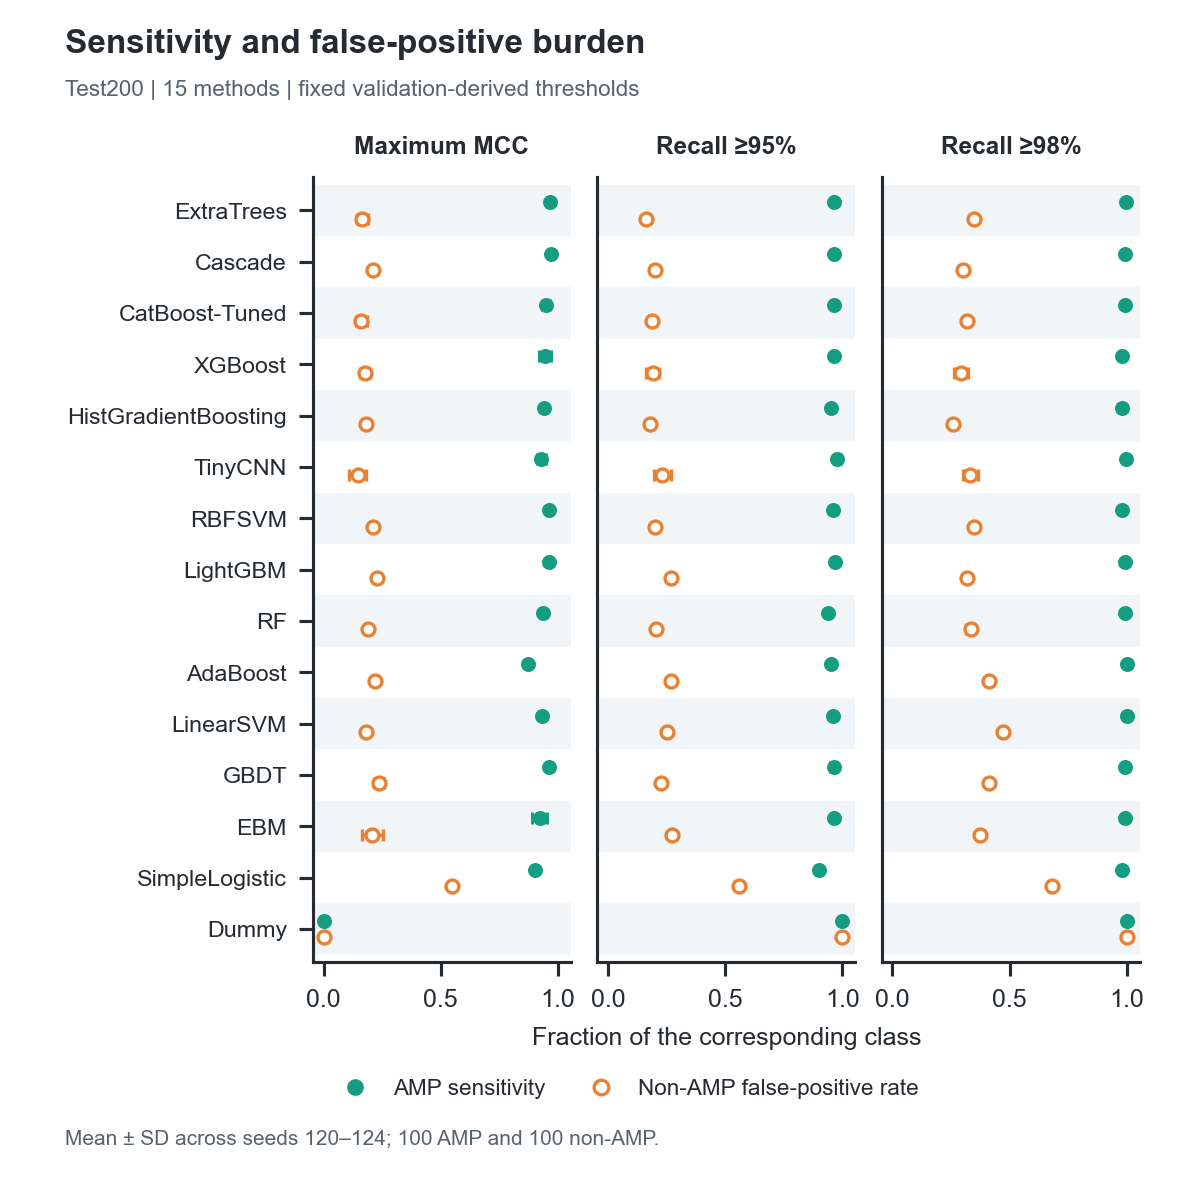

In [2]:
layout_sensitivity, fig_sensitivity = sensitivity()
from IPython.display import display, Image
display(Image(filename=str(ROOT/'Sensitivity_and_false_positive_burden_preview.png')))

## Figure 2. Accuracy and CPU deployment cost

**中文图注。** 15种方法在固定Test200上的AMP AUPRC与单线程CPU处理200条肽的耗时。AUPRC按average precision计算；点及纵向误差线为种子120–124的均值±标准差。每个散点直接标注方法名，引线用于区分密集区域。横轴为对数刻度，使用完整CPU计时表中seed123模型的200肽批量结果；预热3次后重复30次，报告中位数。工作负载为固定Vop序列，包括从原始序列计算特征、预测和sigmoid校准，不含模型加载与文件I/O。计时序列与用于准确率评估的Test200不同。

**English legend.** AMP AUPRC on the fixed Test200 holdout versus single-thread CPU latency for a 200-peptide workload. AUPRC is calculated as average precision; points and vertical error bars show mean ± s.d. across training seeds 120–124. Each method is directly labelled, with leader lines separating labels in crowded regions. The logarithmic time axis uses the full CPU timing results for the seed123 model: the median of 30 repetitions after three warm-up runs. The timing workload uses fixed Vop sequences and includes raw-sequence feature extraction, prediction and sigmoid calibration, excluding model loading and file I/O. Timing inputs are separate from the Test200 accuracy evaluation.


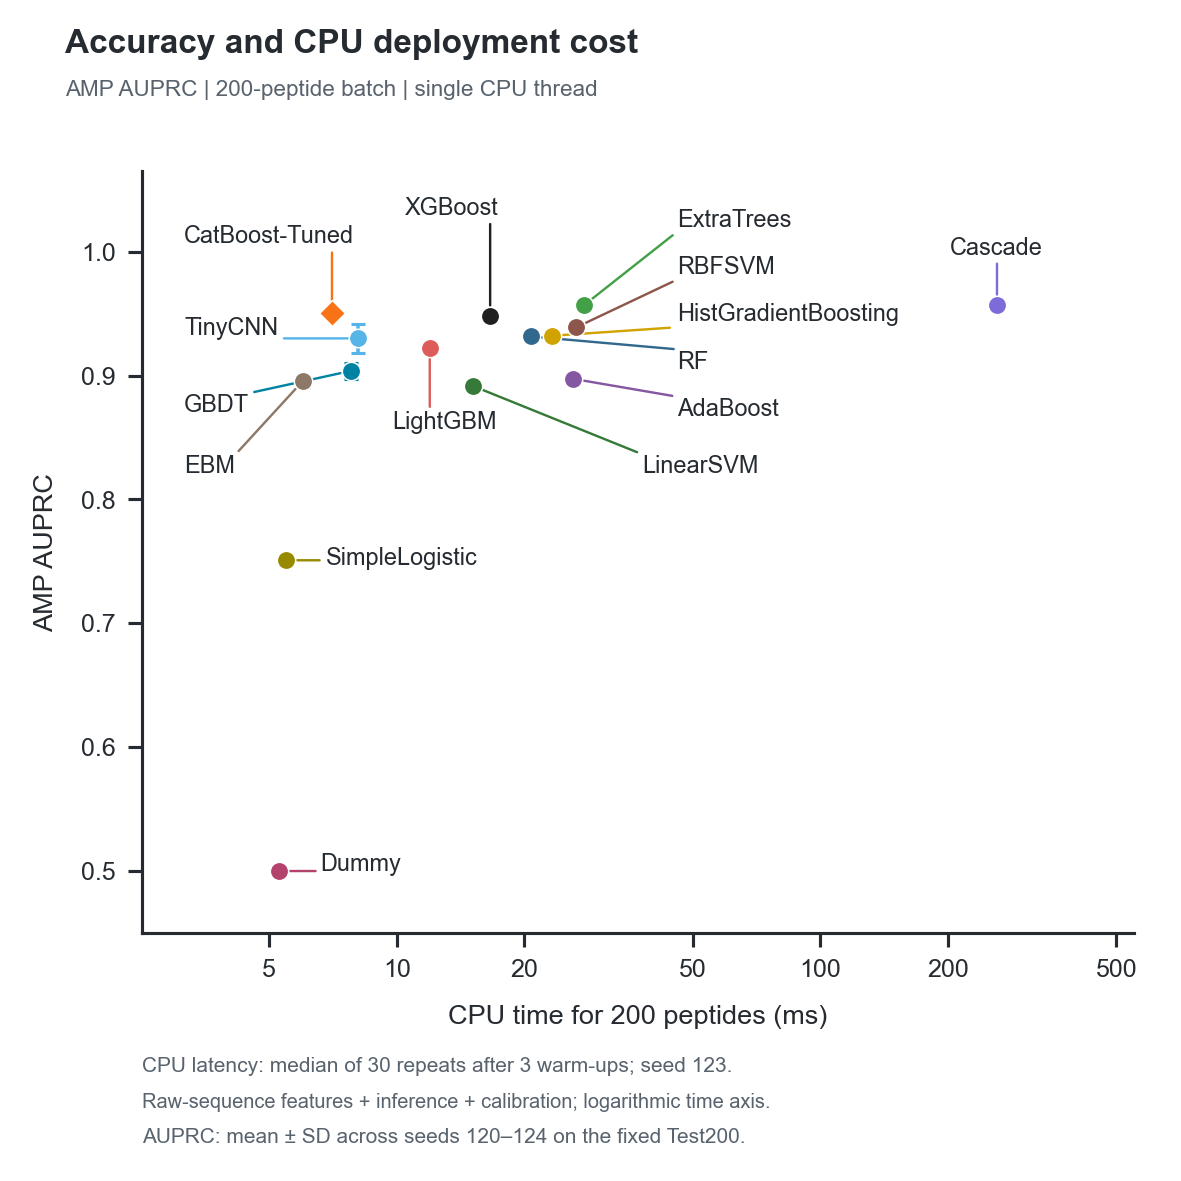

In [3]:
layout_cost, fig_cost = cost()
display(Image(filename=str(ROOT/'Accuracy_and_CPU_deployment_cost_AUPRC_preview.png')))

In [4]:
from matplotlib.backends.backend_pdf import PdfPages
with PdfPages(ROOT/'AMP_classification_selected15_figures.pdf') as pdf:
    pdf.savefig(fig_sensitivity)
    pdf.savefig(fig_cost)
plt.close('all')
print('Exported: two individual PDFs and one two-page PDF, all 200 × 200 mm.')

Exported: two individual PDFs and one two-page PDF, all 200 × 200 mm.
